# Initalize libraries

## Import libraries

In [1]:
import sys, os
import time
from os.path import join
from os import path
from importlib import reload
from getpass import getuser
from tqdm.auto import tqdm
import scipy


#data
import xarray as xr
import h5py

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

# pyFAI
import pyFAI
from pyFAI.azimuthalIntegrator import AzimuthalIntegrator
from pyFAI.detectors import Detector

# Self-written libraries
sys.path.append(join(os.getcwd(), "library"))
import helper_functions as helper
import interactive
from interactive import cimshow
import mask_lib

# Gifs
import imageio

plt.rcParams["figure.constrained_layout.use"] = True  # replaces plt.tight_layout

  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "/asap3/petra3

In [2]:
# Is there a GPU?
try:
    # Cupy
    import cupy as cp
    import cupyx as cpx

    GPU = True

    print("GPU available")

    # Self-written library
    import CCI_core_cupy as cci
except:
    GPU = False
    import CCI_core as cci

    print("GPU unavailable")

parula_map = cci.parula_map()

GPU unavailable


In [3]:
# interactive plotting
import ipywidgets

%matplotlib widget

# Auto formatting of cells
#%load_ext jupyter_black

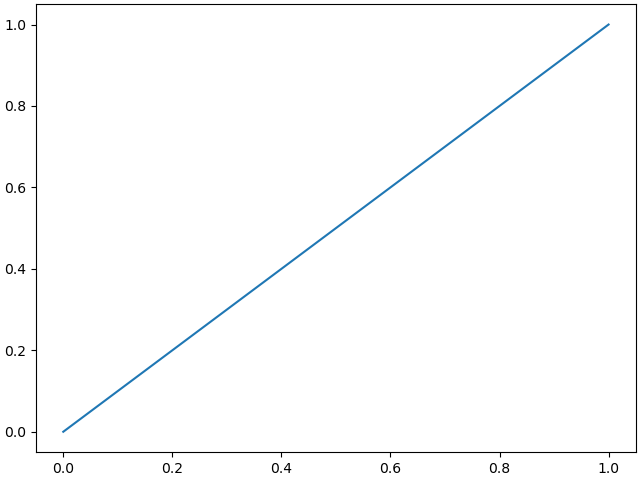

In [4]:
%matplotlib widget
import matplotlib.pyplot as plt
plt.plot([0,1],[0,1])
plt.show()

## Experiment specific Functions

In [5]:
facility = "PETRA" # Options: "SwissFEL", "MAXI"
BEAMTIMEID = 11022228 # Proposal number
data_fname_prefix = "2602_orbitronics"
USER = getuser()

# Number or jobs for analysis
NR_JOBS = 32

# Facility specific loading functions
if facility == "PETRA":
    import PETRA_MaxP04_loading as loading
elif facility == "MAXI":
    import MAXI_loading as loading
elif facility == "SwissFEL":
    from sfdata import SFDataFiles, SFScanInfo, SFProcFile
    import Swiss_FEL_Loading as loading

BASEFOLDER = "/asap3/petra3/gpfs/p04/2026/data/%s/" % BEAMTIMEID
DATAFOLDER = join(BASEFOLDER,"raw")

# Load dictionary for keys etc
mnemonics = loading.load_mnemonics()

### Loading

In [6]:
def generate_filename(scan_nr: int):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """
    return join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}.nxs")

def get_marana_filenames(scan_nr: int, file_indices = None):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """

    scan_count = load_key(scan_nr, "/scan/data/point_nb")
    if np.ndim(scan_count) == 0:
        scan_count = 1
    elif np.ndim(scan_count) > 0:
        scan_count = scan_count.shape[0]

    #this does not work anymore since we are sampling with 200 frames per file -> os.listdir....
    
    names = os.listdir(join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana"))
    names = [name for name in names if name[-2:]=="nx"]
    fnames = np.array([join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana",name) for name in names])
    fnames = np.array(sorted(fnames))
    files = []
    for file in fnames:
        with h5py.File(file, "r") as f:
            if len(f["/entry/instrument/detector/timestamps"][()]) > 3:
                files.append(file)
    fnames = np.array(files)
    if file_indices is not None:
        fnames = fnames[file_indices]
    
        if type(fnames) == str:
            fnames = np.array([fnames])

    
    return fnames

def load_data(scan_id, keypath=mnemonics["collection"], keys=None):
    """
    Load data of all specified keys from keypath

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    keypath : str
        path of nexus file tree to relevant data field
    keys : str or list of strings
        keys to load from keypath

    Output
    ======
    data : dict
        data dictionary of keys
    ======
    author: ck 2024
    """

    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_data(fname, keypath, keys=keys)

    return data


def load_key(scan_id, key):
    """
    Load any kind of data specified by key (path)

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    key : str
        key path of nexus file tree to relevant data field

    Output
    ======
    data : dict
        data dictionaray on single key
    ======
    author: ck 2024
    """
    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_key(fname, key)

    return data
    
def load_images(im_id, file_indices = None):
    """
    Loads images for a given scan id

    Parameter
    =========
    im_id : int
        experimental identifier of image scan

    Output
    ======
    images : array
        stack of all images the correspond to the id
    ======
    author: ck 2024
    """

    # Generate filesnames
    fnames  = get_marana_filenames(im_id, file_indices = file_indices)

    # load data
    images = [loading.load_key(fname,mnemonics["nx_marana"]) for fname in tqdm(fnames)]
    images = np.stack(images)
    
    return images.astype("float32")

# Full image loading procedure
def load_processing(im_id, file_indices = None, binning = 1, crop = None):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images

In [13]:

# Full image loading procedure
def load_processing_singlephoton(im_id, file_indices = None, binning = 1, crop = None, thr=2):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    #temp=images[0].copy()
    
    if thr>0:
        offset=np.average(images[...,-100:,-100:])
        temp=scipy.ndimage.gaussian_filter(images, sigma=1)-offset
        images[temp<thr]=0
    

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images, temp

# Experimental Details

In [14]:
# Dict with most basic experimental parameter
experimental_setup = {
    "ccd_dist": 0.18,  # ccd to sample distance
    "px_size": 11e-6,  # pixel_size of camera
    "binning": 1,  # Camera binning
}

# Setup for azimuthal integrator
detector = Detector(
    experimental_setup["binning"] * experimental_setup["px_size"],
    experimental_setup["binning"] * experimental_setup["px_size"],
)

# General saving folder
folder_general = helper.create_folder(join(BASEFOLDER, "processed"))
print("Output Folder: %s" % folder_general)

Output Folder: /asap3/petra3/gpfs/p04/2026/data/11022228/processed


# Load images


In [15]:
# Specify image ids in iterable like list or array
im_ids = [2319,2320]#[1417]
dark_id = None #iterable; one needs to be assigned for each image

# Which data from nexus files to load? (e.g. "energy","master_energy","srotz","magnet_A", "cryo" ...)
key = "marana_counter"
key = "helicity"

# Use individual image stacks of each scan (e.g., from ascan) id or average of each id?
use_sub_frame = True

# Sorting of data?
sort = False

## Normalize?
normalization = False
norm_key = "maxibeckhoff1adc2_rmean"

print("Loading one dark for all scans")
if dark_id is not None:
    dark_all, _,temp = load_processing_sinfigglephoton(dark_id)

# Load data
images, scan_axis, norm = [], [], []
for i, im_id in enumerate(tqdm(im_ids,desc="Im_ids")):
    # Load scan axis or single image data
    scan_axis.append(load_key(im_id,mnemonics[key]))
    
    # load images
    timage, timages,temp = load_processing_singlephoton(im_id)
    
    if use_sub_frame is True:
        timage = np.mean(timages,axis=1)
        
    ## Load and subtract dark images
    if dark_id is not None:
        timage = timage - dark_all
    
    # Append to data variable
    images.append(timage)

    # Load normalization
    if normalization is True:
        norm.append(load_data(im_id, norm_key))
    else:
        norm.append(np.ones(timage.shape[0]))

print("Data loaded!")

Loading one dark for all scans


Im_ids:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Data loaded!


TypeError: Invalid shape (50, 100, 1023) for image data

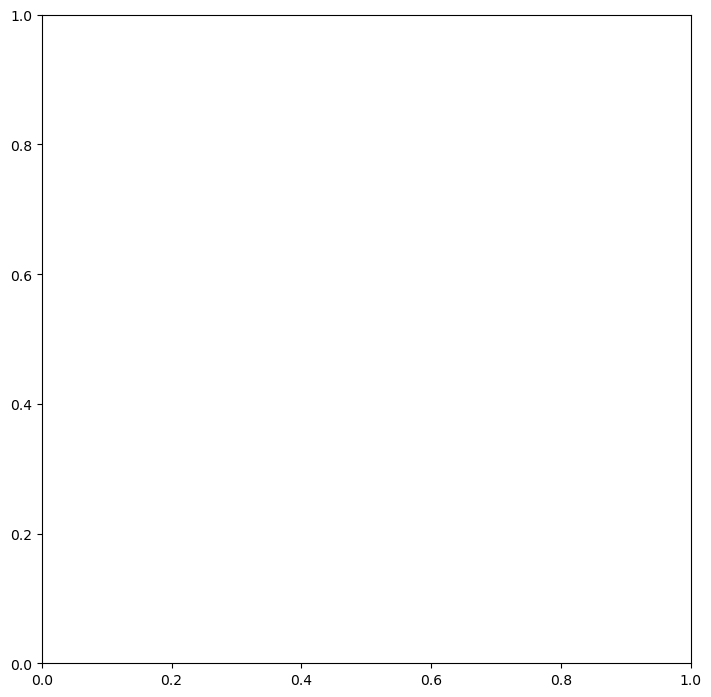

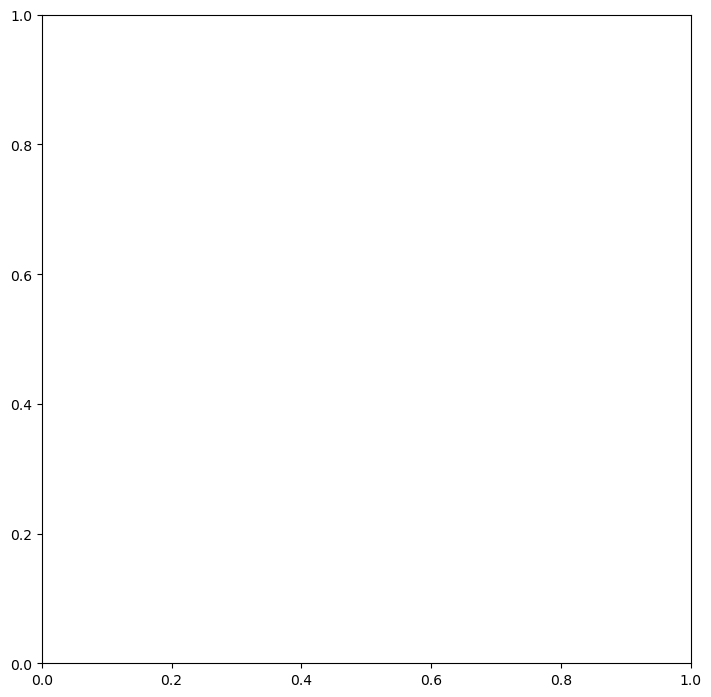

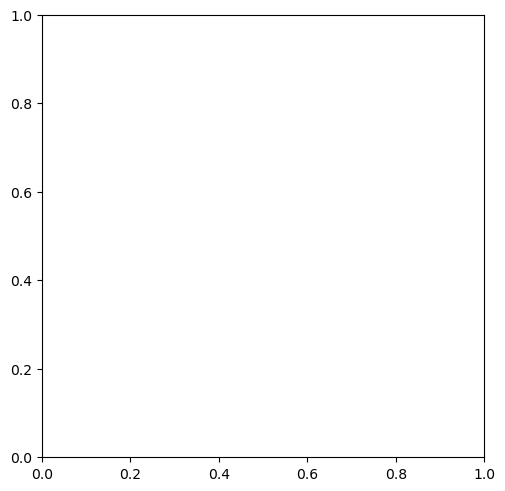

In [19]:

offset=np.average(temp[0,800:,:200])
fig,ax=plt.subplots()
ax.imshow(temp[0,:,:][450:550, 450:550]-offset, vmin=0, vmax=10)

TypeError: Invalid shape (50, 100, 1023) for image data

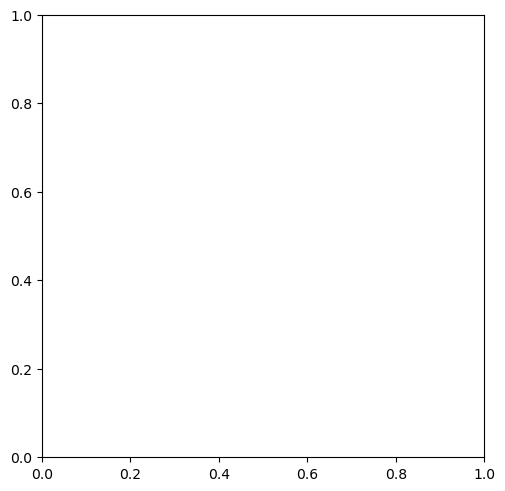

In [20]:

fig,ax=plt.subplots()
ax.imshow(scipy.ndimage.gaussian_filter((temp[0,:,:][450:550, 450:550]-offset), sigma=1), vmin=0, vmax=10)

TypeError: Invalid shape (50, 100, 1023) for image data

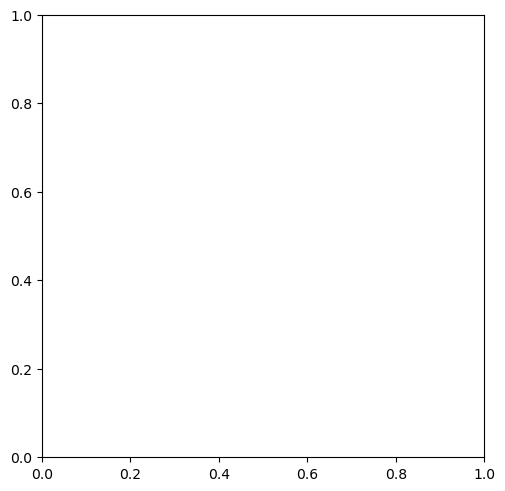

In [21]:
fig,ax=plt.subplots()
ax.imshow(scipy.ndimage.gaussian_filter((temp[0,:,:][450:550, 450:550]-offset), sigma=1)>2)

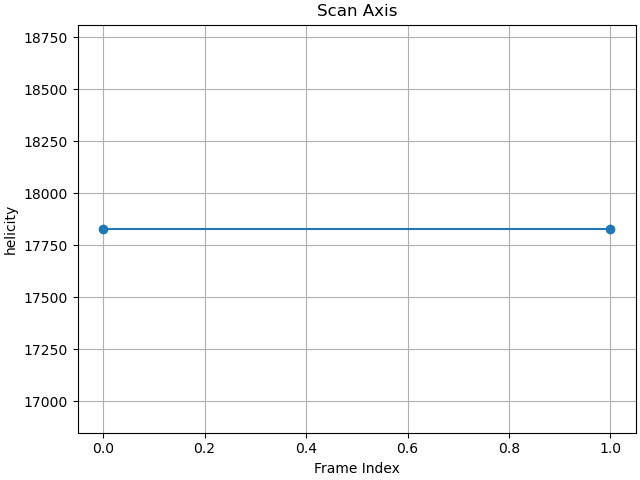

In [10]:


# Get one lambda value
if key == "master_energy":
    energy_lambda = cci.photon_energy_wavelength(scan_axis[0])
else: 
    energy_lambda = cci.photon_energy_wavelength(load_key(im_id, mnemonics["energy"]))

# Ugly handling of use subframes
try:
    scan_axis = np.stack(scan_axis)
except:
    scan_axis = np.concatenate(scan_axis)

try:
    norm = np.stack(norm)
except:
    norm = np.concatenate(norm)

try:
    images = np.stack(images)
except:
    images = np.concatenate(images)

# Squeeze list
images = np.squeeze(images)
scan_axis = np.squeeze(scan_axis)
norm = np.squeeze(norm)

if key == "magnet_A":
    scan_axis = current_to_field(scan_axis)
    key = "magnet_mT"

# Plot scan axis
fig, ax = plt.subplots()
ax.plot(scan_axis, "o-")
ax.set_title("Scan Axis")
ax.set_ylabel(key)
ax.set_xlabel("Frame Index")
ax.grid()

In [11]:
images=np.average(images, axis=1)

interactive(children=(FloatRangeSlider(value=(0.6429950066804886, 4360.077011230512), description='contrast', …

(<Figure size 700x700 with 1 Axes>, <Axes: >)

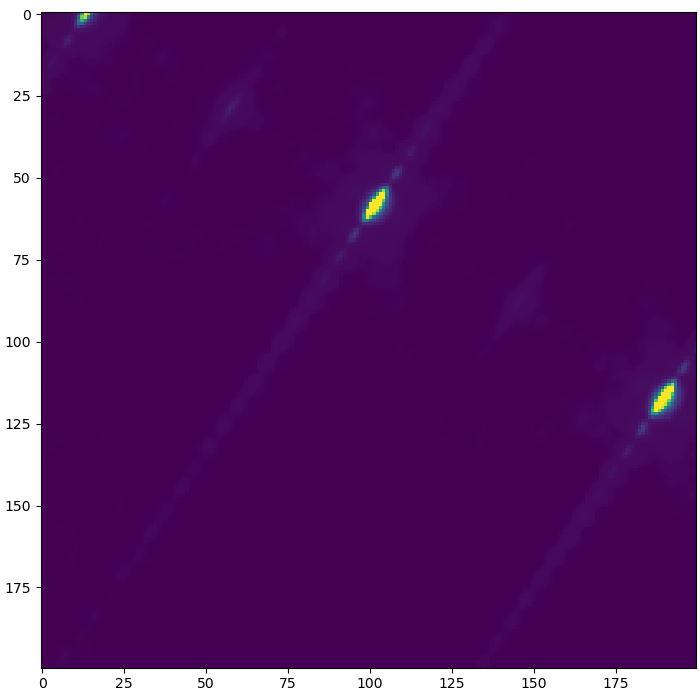

In [12]:
cimshow(images[0][300:500,300:500], vmin=0,vmax=100)

interactive(children=(FloatRangeSlider(value=(-11.827607116699218, 11.577415435791217), description='contrast'…

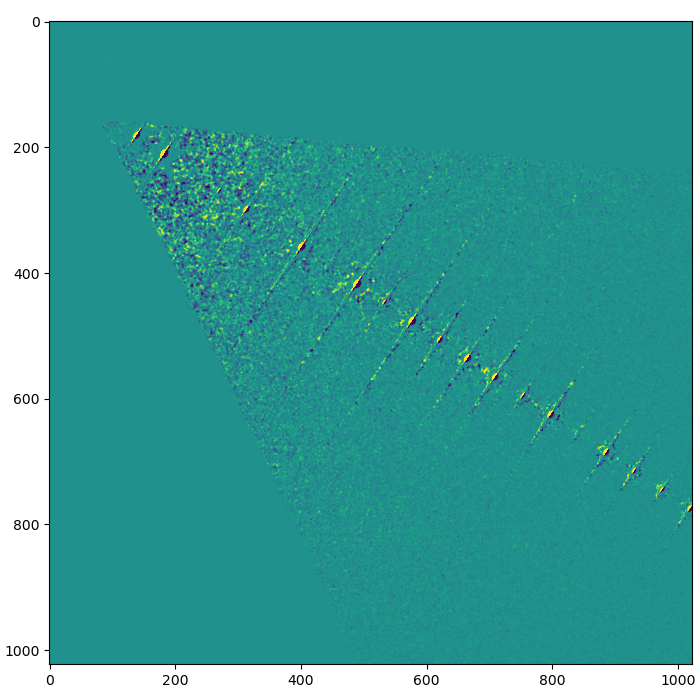

In [15]:


P2=[790,1023]
P1=[50,0]

roi=np.s_[1180:1880, 1110:]
roi=np.s_[:,:]
cimshow((images[0] - images[1])[roi]  )


import numpy as np
from scipy.ndimage import map_coordinates

def line_scan(image, x1, y1, x2, y2, num=None):
    # Length of the line
    length = int(np.hypot(x2 - x1, y2 - y1))
    
    if num is None:
        num = length

    # Generate line coordinates
    x = np.linspace(x1, x2, num)
    y = np.linspace(y1, y2, num)

    # Extract values with interpolation
    coords = np.vstack((y, x))  # note: (row, col) = (y, x)
    values = map_coordinates(image, coords, order=1)

    return values

In [31]:
images[0].shape

(1023, 1023)

Linear Fit: 0.9993*x + -0.0464


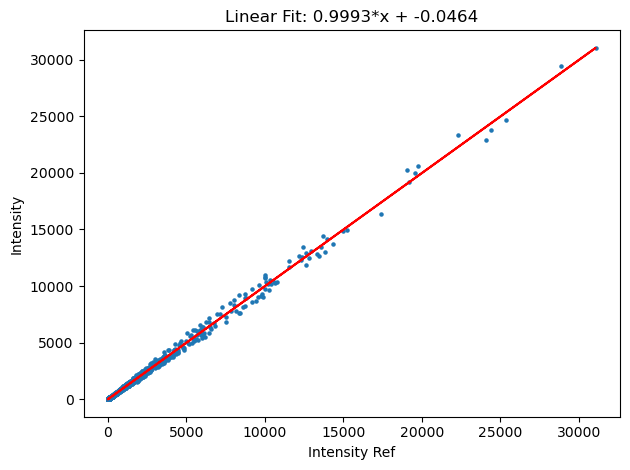

In [32]:
#normalize
im_c=images[0].copy()
topo_c=images[1].copy()

# Get scaling factor and offset
factor, offset = cci.dyn_factor(
    im_c ,
    topo_c ,
    method="correlation",
    verbose=True,
    plot=True,
)

diff_c = im_c / factor - topo_c - offset
sum_c = im_c / factor + topo_c - offset

(-10.0, 10.0)

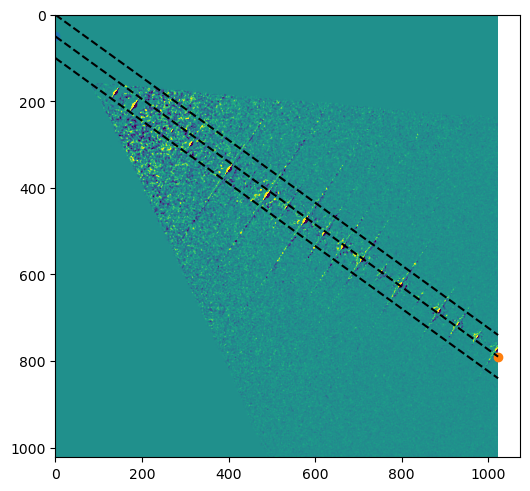

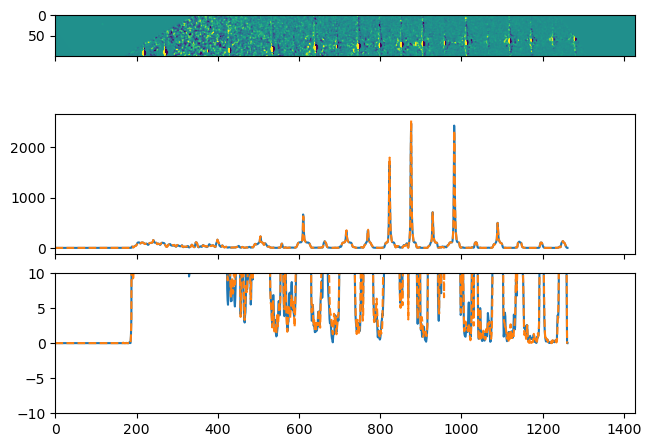

In [33]:
roi=np.s_[:,:]
fig,ax=plt.subplots()
ax.imshow((diff_c)  , vmin=-10, vmax=10)
ax.scatter(P1[1], P1[0])
ax.scatter(P2[1], P2[0])
ax.plot([P1[1], P2[1]],[P1[0]-50, P2[0]-50], ls="--", c="k")
ax.plot([P1[1], P2[1]],[P1[0]+50, P2[0]+50], ls="--", c="k")

ax.plot([P1[1], P2[1]],[P1[0], P2[0]], ls="--", c="k")


theta = np.arctan2(P1[1]- P2[1],P1[0]- P2[0])          # radians
theta_deg = np.degrees(theta)       # degrees
from scipy.ndimage import rotate
diff2 = rotate(diff_c, angle=-theta_deg-90, reshape=True, order=1, mode="constant", cval=0.0)
diff2=diff2[622-50:622+50]

fig,ax=plt.subplots(3,1, sharex=True)
ax[0].imshow((diff2)  , vmin=-10, vmax=10)
linescan=line_scan((images[0]), P1[1], P1[0], P2[1], P2[0], num=None)
ax[1].plot(linescan)
ax[2].plot(linescan)
linescan=line_scan((images[1]), P1[1], P1[0], P2[1], P2[0], num=None)
ax[1].plot(linescan, ls="--")
ax[2].plot(linescan, ls="--")
ax[2].set_ylim(-10,10)

interactive(children=(IntSlider(value=0, description='nr', max=1), Output()), _dom_classes=('widget-interact',…

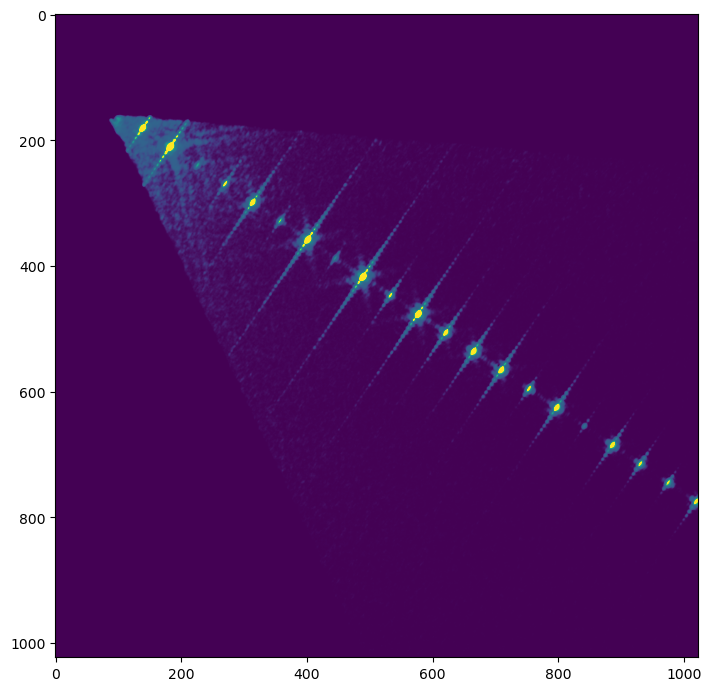

In [77]:
# Assign to xarray
# Setup xarray for images
data = xr.Dataset()
data[key] = xr.DataArray(scan_axis, dims=["index"])
data["images"] = xr.DataArray(images, dims=["index", "y", "x"])

data["image"] = data["images"].mean("index")
image = data["image"].values

# Sort ascending key
if sort is True:
    data = data.sortby(key,ascending = False)

# Assign im_id as attribute
data = data.assign_attrs({"im_id": im_id})

# Slideshow viewer
fig, ax = cimshow(data["images"])

# Draw beamstop mask

In [ ]:
poly_mask = interactive.draw_polygon_mask(image)

In [ ]:
# Take poly coordinates and mask from widget
p_coord = poly_mask.get_vertice_coordinates()
mask_draw = poly_mask.full_mask.astype(int)

print("Copy these coordinates into the 'load_poly_coordinates()' function:")
print(p_coord)

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
tmp = image * (1 - mask_draw)
mi, ma = np.percentile(tmp[tmp != 0], [0.1, 99.9])
ax[0].imshow(image * (1 - mask_draw), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask_draw)")

mi, ma = np.percentile(image * mask_draw, [0.1, 99.9])
ax[1].imshow(image * mask_draw, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask_draw")

ax[2].imshow(1 - mask_draw)
ax[2].set_title("1 - mask_draw")

In [ ]:
def load_poly_coordinates():
    """
    Dictionary that stores polygon corner coordinates of all drawn masks
    Example: How to add masks with name "test":
    mask_coordinates["test"] = copy coordinates from above
    """

    # Setup dictonary
    mask_coordinates = dict()

    # Setup dictonary
    mask_coordinates = dict()

    # Mask #1
    mask_coordinates["riccardo_cocoon"] = [[(793.6, 989.6), (793.6, 996.8), (902.7, 1094.6), (925.4, 1121.4), (923.3, 1126.6), (585.5, 1204.8), (588.6, 1222.3), (921.3, 1156.4), (927.4, 1159.5), (929.5, 1172.9), (898.6, 1217.2), (903.7, 1225.4), (895.5, 1257.3), (907.9, 1258.4), (946.0, 1187.3), (957.3, 1175.0), (969.7, 1183.2), (1031.4, 1437.6), (1058.2, 1510.7), (997.5, 1194.5), (1007.8, 1189.4), (1147.8, 1290.3), (1143.7, 1272.8), (1011.9, 1162.6), (1016.0, 1152.3), (1089.1, 1180.1), (1095.3, 1163.6), (1028.4, 1134.8), (1248.7, 1086.4), (1411.4, 1052.4), (1402.2, 1035.9), (1028.4, 1103.9), (1121.0, 1006.1), (1101.5, 995.8), (1011.9, 1095.7), (1000.5, 1084.3), (1055.1, 971.0), (1038.7, 964.9), (982.0, 1065.8), (973.8, 1061.7), (881.1, 670.3), (865.6, 677.6), (942.9, 1062.7), (940.8, 1094.6)]]
    mask_coordinates["epoxy_bs"] = [[(1053.4, 996.4), (1048.2, 988.8), (1042.6, 984.0), (1033.7, 978.3), (1028.1, 975.1), (1022.8, 973.6), (1022.4, 959.6), (1025.2, 957.3), (1025.4, 948.4), (1025.2, 939.4), (1022.9, 929.4), (1019.4, 922.1), (1012.3, 912.2), (1014.4, 910.0), (1014.4, 903.4), (1011.3, 892.9), (1016.8, 889.2), (1017.9, 886.0), (1010.5, 875.0), (1009.6, 873.2), (985.9, 663.4), (969.1, 535.8), (952.7, 379.3), (929.7, 224.2), (888.5, -5.7), (881.7, -5.7), (901.1, 94.5), (924.5, 226.7), (946.3, 382.0), (963.0, 551.6), (976.6, 666.6), (994.4, 822.5), (1000.5, 875.4), (997.3, 884.2), (999.3, 892.2), (1004.1, 894.2), (1006.5, 915.1), (1012.5, 956.3), (1013.3, 963.5), (1009.3, 970.7), (1009.3, 976.3), (1000.2, 983.7), (989.8, 995.3), (983.4, 1010.2), (982.2, 1028.6), (987.8, 1048.2), (1003.4, 1063.4), (1020.7, 1077.5), (1026.7, 1084.3), (1030.2, 1108.3), (1041.4, 1210.0), (1053.8, 1335.8), (1069.4, 1462.5), (1075.8, 1523.8), (1086.3, 1654.8), (1094.8, 1754.0), (1109.7, 1910.7), (1108.5, 1928.6), (1095.7, 2052.7), (1103.3, 2050.7), (1120.5, 1910.1), (1117.3, 1896.7), (1098.1, 1692.0), (1084.9, 1526.5), (1072.2, 1414.7), (1061.4, 1311.0), (1045.8, 1178.4), (1034.9, 1075.3), (1041.8, 1068.9), (1052.6, 1054.5), (1059.4, 1038.8), (1062.2, 1020.4), (1057.8, 1004.0)]]
    mask_coordinates["bs_medium"] = [[(20.4, 1214.8), (816.5, 1085.8), (874.2, 1006.2), (915.4, 981.5), (745.2, 9.6), (833.0, 9.6), (915.4, 369.3), (981.3, 888.1), (989.5, 940.3), (973.0, 970.5), (1006.0, 984.2), (1058.1, 1028.1), (1074.6, 1061.1), (2021.7, 915.6), (2030.0, 1017.2), (1398.5, 1085.8), (1091.1, 1116.0), (1058.1, 1173.6), (1000.5, 1214.8), (1124.0, 2008.2), (1044.4, 2016.4), (956.5, 1492.1), (945.6, 1228.5), (893.4, 1198.3), (833.0, 1143.4), (9.4, 1305.4)]]
    mask_coordinates["bs_large"] =[[(-9.52514267623522, 988.0244972208288), (133.8623449984891, 1003.0301645356255), (444.7643270650601, 1004.8352658735243), (677.4009610677929, 1006.3647572722471), (999.1891601517673, 998.0282754306933), (1008.9687632034429, 924.746257259271), (1002.856550157784, 753.6042842087398), (990.8526783102134, 392.799693733892), (977.5143073637275, -17.355212870551895), (1009.1929383616316, -5.684138292376701), (1027.5331984130498, 374.4594336824738), (1040.871569359536, 736.2627456059059), (1047.540754832779, 842.9697131777938), (1049.2080512010896, 983.0226081158966), (1113.8991502915467, 991.4702430486711), (1282.2960834909322, 986.4683539437389), (1529.0559460009226, 968.1280938923206), (1872.5189978729368, 933.1148701577949), (1955.8838162884742, 928.1129810528627), (2022.575671020904, 939.784055631038), (2029.2448564941471, 996.4721321536034), (1947.5473344469203, 974.7972793655637), (1627.4264317312568, 998.139428521914), (1333.9822709085652, 1019.8142813099539), (1133.9067067112755, 1031.485355888129), (955.5059953020256, 1034.8199486247506), (921.8266086621485, 1036.8207042667236), (678.7348313316545, 1045.0328414964195), (469.98929284993585, 1046.824482476588), (116.52246276805741, 1046.824482476588), (-6.8574684869379325, 1023.4823333202376)], [(-18.49404559764608, 785.86607528193), (-15.741149396111126, -20.73251176780832), (1721.3363537724376, -15.226719364738301), (2061.961377109028, -16.878457085658965), (2070.998269815253, 2083.925571530775), (-33.65294626451481, 2100.746691469454), (-41.88066798492048, 1173.7567109934555), (-50.10838970532615, 731.8366354770906), (43.139123125938, 737.3217832910489), (81.53515782116438, 62.64860221779031), (960.9090655017594, 46.10727357274732), (1962.9632828604786, 59.87175458042202), (2008.0241868014546, 946.3583113396406), (1981.6954772961565, 1969.1555403163811), (838.0421581597698, 2002.0664271980036), (56.04291820032506, 1965.3159367546796), (34.102326945909965, 1019.127939000208), (36.84490085271187, 742.1279744132175)]]
    mask_coordinates["SAXS_FeRh"] = [[(773.2, -6.0), (822.3, 268.9), (885.4, 633.9), (907.3, 894.6), (921.8, 978.5), (869.1, 1017.1), (832.2, 1080.2), (762.3, 1094.7), (-15.4, 1232.9), (-10.5, 1294.2), (761.9, 1147.0), (836.0, 1133.3), (865.4, 1186.2), (909.7, 1211.8), (945.3, 1223.9), (964.9, 1441.9), (990.4, 1625.2), (1000.5, 1717.6), (1048.0, 1976.4), (1097.4, 2067.0), (1155.0, 2080.7), (1314.3, 2081.8), (1227.0, 1815.1), (1186.1, 1707.1), (1151.5, 1605.4), (1043.5, 1272.1), (1004.2, 1217.3), (1066.2, 1184.7), (1097.2, 1119.4), (1204.9, 1108.0), (1860.8, 1024.8), (1968.5, 1008.4), (2043.4, 1016.0), (2101.0, 952.9), (2079.1, 892.5), (1886.9, 936.7), (1660.1, 975.8), (1425.2, 1010.1), (1266.9, 1036.2), (1091.7, 1057.1), (1055.7, 1007.6), (982.9, 973.6), (982.9, 949.3), (968.4, 926.0), (934.4, 597.9), (909.1, 428.0), (860.4, 144.0), (829.5, -16.6)]]
    return mask_coordinates

In [ ]:
# Which drawn masks do you want to load? Use can combine multiple masks, e.g., ["bs_left_part", "bs_bot_part", "bs_top_part"]
polygon_names = ["SAXS_FeRh"]
mask = mask_lib.load_poly_masks(
    experimental_setup["binning"] * np.array(image.shape),
    load_poly_coordinates(),
    polygon_names,
)

# optional binning
mask = helper.binning(mask,experimental_setup["binning"])

## Finetuning of mask position

In [ ]:
# Use widget to shift and expand or shrink the mask
ss_mask = interactive.Shift_Scale_Mask(images[-1], mask, shift=[-1.5, -5], scale=-3)

In [ ]:
# Take mask, shift and scaling from widget
mask, mask_shift, mask_scale = ss_mask.get_mask()

In [ ]:
# Add to xarray
data["mask"] = xr.DataArray(mask, dims=["y", "x"])

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(image, [0.1, 99.9])
ax[0].imshow(image, cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask)")

mi, ma = np.percentile(image * mask, [0.1, 99.9])
ax[1].imshow(image * mask, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask")

ax[2].imshow(1 - mask)
ax[2].set_title("1 - mask")
plt.tight_layout()

## Basic widget to find center

Try to **align** the circles to the **center of the scattering pattern**. Care! Position of beamstop might be misleading and not represent the actual center of the hologram. 

In [ ]:
# Set center position via widget
c0, c1 = 1106, 970 # initial values
ic = interactive.InteractiveCenter(data["images"], c0=c0, c1=c1)

In [ ]:
# Get center positions
center = [ic.c0, ic.c1]
print(f"Center:", center)

## Azimuthal integrator widget for finetuning
If scattering pattern is radial symmetric, move center position until scattering ring is a line after transformation in polar coordinates

In [ ]:
# Setup azimuthal integrator for virtual geometry
ai = AzimuthalIntegrator(
    dist=experimental_setup["ccd_dist"],
    detector=detector,
    wavelength=energy_lambda,#experimental_setup["lambda"],
    poni1=center[0]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # y (vertical)
    poni2=center[1]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # x (horizontal)
)

In [ ]:
# Calc azimuthal integration
I_t, q_t, phi_t = ai.integrate2d(
    image,
    700,
    radial_range=(0.025, .35),
    unit="q_nm^-1",
    correctSolidAngle=True,
    dummy=np.nan,
    mask=mask,
    method = "BBox"
)
az2d = xr.DataArray(I_t, dims=("phi", "q"), coords={"q": q_t, "phi": phi_t})

# Plot
fig, ax = plt.subplots()
mi, ma = np.nanpercentile(I_t, [1, 98])
az2d.plot.imshow(ax=ax, vmin=mi, vmax=ma)
plt.title(f"Azimuthal integration")

In [ ]:
aic = interactive.AzimuthalIntegrationCenter(
    image * (2 - mask),
    ai,
    c0=center[0],
    c1=center[1],
    im_data_range=[1, 95],
    radial_range=(0.02, 0.3),
    qlines=[40, 60],
    mask=mask,
    circle_radius=100,
)

In [ ]:
# Get center positions
center = [aic.c0, aic.c1]
data = data.assign_attrs({"center": center})
print(f"Center:", center)

# Azimuthal integration for all images

In [ ]:
# Update center of azimuthal integrator
ai = AzimuthalIntegrator(
    dist=experimental_setup["ccd_dist"],
    detector=detector,
    wavelength=energy_lambda,
    poni1=center[0]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # y (vertical)
    poni2=center[1]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # x (horizontal)
)

In [ ]:
# Do 2d Azimuthal integration of all images and append them to list
list_q, list_i2d = [], []
for i, im in enumerate(tqdm(data["images"].values)):
    # Adapt azimuthal integrator if scan is an energy scan
    if key == "energy":
        ai.wavelength = cci.photon_energy_wavelength(
            data["energy"][i].values, input_unit="eV"
        )

    # Calc ai
    i2d, q, chi = ai.integrate2d(
        im,
        500,
        90,
        radial_range=(0.0, 0.5),
        unit="q_nm^-1",
        correctSolidAngle=True,
        dummy=np.nan,
        mask=mask,
        method = "BBox"
    )
    list_q.append(q)
    list_i2d.append(i2d)

# Add to xarrays
data["q"] = q
data["chi"] = chi
data["i2d"] = xr.DataArray(list_i2d, dims=["index", "chi", "q"])

## Select relevant chi-range

In [ ]:
# Plot 2d and 1d azimuthal integration to estimate the relevant chi and q range
# which image to show?
idx = -1

# Select chi-range
# Which chi-mode? ("all","other")
chi_mode = "all"

# Select chi-range
if chi_mode == "all":
    sel_chi = (data.chi <= 180) * (data.chi >= -180)
elif chi_mode == "other":
    sel_chi = (
        (data.chi <= 139) * (data.chi >= 132)
        + (data.chi <= 47) * (data.chi >= 41)
        + (data.chi <= -40) * (data.chi >= -48)
        + (data.chi <= -133) * (data.chi >= -140)
    )
data["i1d"] = data.i2d.where(sel_chi, drop=True).mean("chi")

# Plot
fig, ax = plt.subplots(
    2,
    1,
    figsize=(8, 8),
    sharex=True,
)
mi, ma = np.nanpercentile(data["i2d"][idx], [0.1, 99.9])
data["i2d"][idx].plot.imshow(ax=ax[0], vmin=mi, vmax=ma)
ax[0].set_title(f"2d Azimuthal integration")
ax[0].grid()

# Plot 1d azimuthal integration to estimate the relevant q-range
ax[1].plot(data.q, data.i1d[idx])
ax[1].set_yscale("log")
ax[1].set_title("1d Azimuthal Integration")
ax[1].grid()
ax[1].set_ylabel("Integrated intensity")
ax[1].set_xlabel("q")

## Select relevant q-range

In [ ]:
# Select relevant q-range for averaging
q0, q1 = 0.025, 0.2
binning = False
bins = []

# Get SAXS from q-range
sel = (data.q > q0) * (data.q < q1)

data["saxs"] = data.i1d.where(sel, drop=True).mean("q")

# Averaging of same scan axis values or binning
if binning is True:
    # Execute binning
    data_bin = data.groupby_bins(key, bins).mean()

    # Rename binned values, drop intervals as those cannot be save in h5
    bin_scan_axis = scan_axis + "_bins"
    data_bin = data_bin.swap_dims({bin_scan_axis: key})
    data_bin = data_bin.drop(bin_scan_axis)
else:
    _, count = np.unique(data[key].values, return_counts=True)
    if np.any(count > 1):
        data_bin = data.groupby(key).mean()
    else:
        data_bin = data.swap_dims({"index": key})

In [ ]:
# Plot Averaged 1d Intensity over q for all different scan 
fig, ax = plt.subplots()
colors = plt.cm.jet(np.linspace(0,1,len(data_bin[key])))

for i, i1dchi in enumerate(data_bin["i1d"].values):
    #i1dchi = i1dchi - np.nanmin(i1dchi)
    ax.plot(data_bin["q"],i1dchi/np.nanmax(i1dchi),label="%s: %.2f"%(key,data_bin[key][i]),color = colors[i])
    
ax.grid()
ax.legend(ncol = 2,fontsize = 8)
ax.set_xlabel("q")
ax.set_ylabel("Averaged Intensity")
ax.set_ylim([0.01,1])
ax.set_xlim([q0,q1])
#ax.set_yscale("log")

## Title and fname
if len(im_ids) > 1:
    ax.set_title("Scan Id %s-%s" % (im_ids[0], im_ids[-1]))
    fname = "SAXS_i1d_ImId_%04d-%04d_%s.png" % (im_ids[0], im_ids[-1], USER)
else:
    ax.set_title("Scan Id %d" % (im_ids[0]))
    fname = "SAXS_i1d_ImId_%04d_%s.png" % (im_ids[0], USER)

fname = join(folder_general, fname)
print("Saving:%s" % fname)
plt.savefig(fname)

# Plotting

In [ ]:
# Plot Intensity of SAXS Pattern
fig, ax = plt.subplots()
ax.plot(data_bin[key].values, data_bin["saxs"].values)
ax.grid()
ax.set_xlabel(key)
ax.set_ylabel("Integrated SAXS")

## Title and fname
if len(im_ids) > 1:
    ax.set_title("Scan Id %s-%s" % (im_ids[0], im_ids[-1]))
    fname = "SAXS_ImId_%04d-%04d_%s.png" % (im_ids[0], im_ids[-1], USER)
else:
    ax.set_title("Scan Id %d" % (im_ids[0]))
    fname = "SAXS_ImId_%04d_%s.png" % (im_ids[0], USER)

fname = join(folder_general, fname)
print("Saving:%s" % fname)
plt.savefig(fname)

In [ ]:
# Plot I(q,t) and integrated intensity
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(6, 4.5), sharex=True)

# Create log plot
data_bin["i1dlog"] = np.log10(data_bin["i1d"]+ 1)

#vmin, vmax = data_bin["i1d"].min(), data_bin["i1d"].max()
vmin, vmax = np.nanpercentile(data_bin["i1dlog"], [60, 99])
data_bin["i1dlog"].plot.contourf(
    x=key,
    y="q",
    ax=ax[0],
    cmap="viridis",
    add_colorbar=False,
    vmin=vmin,
    vmax=vmax,
    levels=100,
    ylim = [q0,q1]
)

ax[1].plot(data_bin[key], data_bin["saxs"], "o-")
ax[1].grid()
ax[1].set_ylabel("total scattered intensity")
ax[1].set_xlabel(key)
ax[1].invert_xaxis()

fig.suptitle(f"ImId:{im_ids}")

fname = join(folder_general, "SAXS_ImId_%s_%s.png" % (im_ids, USER))
print("Saving: %s" % fname)
plt.savefig(fname)

# Export scan as gif

## Select roi of images for plotting

How to use:
1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

In [ ]:
fig, ax = cimshow(data_bin["images"].values)

In [ ]:
# Takes start and end of x and y axis
roi = interactive.axis_to_roi(ax)
print(f"Image registration roi:", roi)

## Plotting

In [ ]:
# Setup gif
folder_gif = helper.create_folder(join(folder_general, "ImId_%05d" % im_id))
variable_images_1d = []

# Find global max and min all images
allmin, allmax = np.nanpercentile(data_bin["i2d"].values, [0.1, 100])
allImin = data_bin.i1d.where(sel, drop=True).min()
allImax = data_bin.i1d.where(sel, drop=True).max()

if allImin <0.1:
    allImin = 0.1
if allmin <0.1:
    allmin = 0.1

# Loop over images
for i in tqdm(range(len(data_bin[key].values))):
    # Plot for averaged image
    fig = plt.figure(figsize=(6, 10))
    gs1 = gridspec.GridSpec(
        4,
        1,
        figure=fig,
        left=0.2,
        bottom=0.05,
        right=0.975,
        top=1.1,
        wspace=0,
        hspace=0,
        height_ratios=[6, 1, 2, 1],
    )

    # Plot image roi
    ax0 = fig.add_subplot(gs1[0])
    tmp = data_bin["images"][i].values[roi]
    tmp[tmp<allmin] = allmin
    m = ax0.imshow(data_bin["images"][i].values[roi], norm = LogNorm(vmin = allImin, vmax=allImax))
    plt.colorbar(m, ax=ax0, pad=0.045, location="bottom")

    # Plot 1d azimuthal integration
    ax1 = fig.add_subplot(gs1[1])
    tmp = data_bin.i1d[i]
    ax1.plot(data_bin.q, tmp)
    ax1.set_xlabel("q")
    ax1.set_ylabel("Mean Intensity")
    ax1.set_xlim([q0, q1])
    ax1.set_ylim([allImin, allImax])
    ax1.set_yscale("log")
    ax1.grid()

    # Contor plot
    ax2 = fig.add_subplot(gs1[2])
    vmin, vmax = np.nanpercentile(data_bin["i1dlog"], [1, 99.9])
    data_bin["i1dlog"].plot.contourf(
        x=key,
        y="q",
        ax=ax2,
        cmap="viridis",
        add_colorbar=False,
        vmin=vmin,
        vmax=vmax,
        levels=200,
        ylim = [q0,q1]
    )
    ax2.vlines(data_bin[key].values[i], q0, q1,'r')
    ax2.hlines(q0, data_bin[key].min(),data_bin[key].max(),'w',linestyles='dashed')
    ax2.hlines(q1, data_bin[key].min(),data_bin[key].max(),'w',linestyles='dashed')

    # Plot SAXS Intensity
    ax3 = fig.add_subplot(gs1[3])
    ax3.plot(data_bin[key].values, data_bin["saxs"].values)
    ax3.scatter(data_bin[key].values[i], data_bin["saxs"].values[i], 20, color="r")
    ax3.set_xlabel(key)
    ax3.set_ylabel("Mean intensity")
    ax3.grid()
    ax3.set_xlim(data_bin[key].min(),data_bin[key].max())

    # Title and fname
    ax0.set_title(
        f"%04d - %04d %s = %s"
        % (im_ids[0], im_ids[-1], key, np.round(data_bin[key].values[i], 3))
    )
    fname = "SAXS_ImId_%04d_%04d_%03d_%s.png" % (im_ids[0], im_ids[-1], i, USER)

    # Save
    fname = path.join(folder_gif, fname)
    variable_images_1d.append(fname)
    plt.savefig(fname)
    plt.close()

# Create gif for 1d AI
if len(im_ids) > 1:
    fname = f"SAXS_ImId_%04d_%04d_%s.gif" % (im_ids[0], im_ids[-1], USER)
else:
    fname = f"SAXS_ImId_%04d_%s.gif" % (im_ids[0], USER)

gif_path = path.join(folder_general, fname)
print("Saving gif:%s" % gif_path)
helper.create_gif(variable_images_1d,gif_path,fps=4)
print("Done!")

In [ ]:
# Drop images
data_bin_save = data_bin.drop_vars(["images"])

# Save log
folder = join(folder_general, "Logs")
helper.create_folder(folder)
fname = join(folder, "SAXS_Log_ImId_%04d_%s.nc" % (im_id, USER))

print(f"Saving:", fname)
data_bin_save.to_netcdf(fname)